# 36. Numerical Linear Algebra
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Forward error is condition number times backward error. Solving $Ax=b$ by Gaussian elimination with partial pivoting for $200$ random matrices with prescribed condition numbers $10^1$ to $10^{15}$: the relative error of the solution (dots) tracks $\kappa(A)\,u$ (line), while the relative residual $\lVert b-A\hat x\rVert/(\lVert A\rVert\lVert\hat x\rVert)$ (grey), a measure of backward error, stays near $u$ regardless of conditioning.

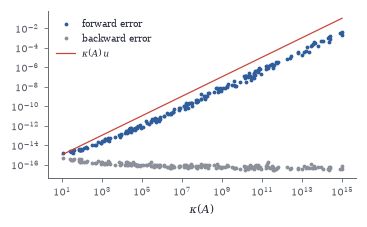

In [2]:
rng = np.random.default_rng(0); n = 60; u = 2.0 ** -53; out = []
for _ in range(200):
    kappa = 10 ** rng.uniform(1, 15); U, _ = np.linalg.qr(rng.normal(size=(n, n))); V, _ = np.linalg.qr(rng.normal(size=(n, n)))
    A = U @ np.diag(np.geomspace(1, 1 / kappa, n)) @ V.T; x = rng.normal(size=n); b = A @ x; xh = np.linalg.solve(A, b)
    out.append((kappa, np.linalg.norm(xh - x) / np.linalg.norm(x), np.linalg.norm(b - A @ xh) / (np.linalg.norm(A, 2) * np.linalg.norm(xh))))
out = np.array(out); kk = np.logspace(1, 15, 50)
fig, ax = plt.subplots(figsize=(W * 0.7, 1.95))
ax.loglog(out[:, 0], out[:, 1], ".", color=BLUE, ms=3, label="forward error"); ax.loglog(out[:, 0], out[:, 2], ".", color=GRAY, ms=3, label="backward error")
ax.loglog(kk, kk * u, color=RED, lw=0.8, label=r"$\kappa(A)\,u$"); ax.set_xlabel(r"$\kappa(A)$"); ax.legend(fontsize=6)

Growth factors in Gaussian elimination with partial pivoting. For random Gaussian matrices (blue, median and range over $20$ trials per size) the growth factor $\rho_n$ grows slowly, roughly like $\sqrt n$. For Wilkinson's matrix (red) it is $2^{n-1}$, the worst case.

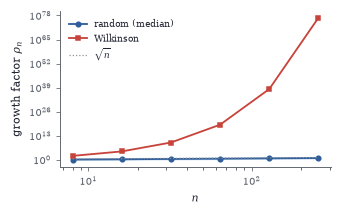

In [3]:
def growth(A):
    A = A.astype(float).copy(); n = len(A); mx = np.abs(A).max(); g = mx
    for k in range(n - 1):
        p = k + np.argmax(np.abs(A[k:, k])); A[[k, p]] = A[[p, k]]; A[k + 1:, k:] -= np.outer(A[k + 1:, k] / A[k, k], A[k, k:]); g = max(g, np.abs(A[k + 1:, k + 1:]).max())
    return g / mx
ns = [8, 16, 32, 64, 128, 256]; rng = np.random.default_rng(1); med, lo, hi, wil = [], [], [], []
for n in ns:
    gs = [growth(rng.normal(size=(n, n))) for _ in range(20)]; med.append(np.median(gs)); lo.append(min(gs)); hi.append(max(gs))
    Wk = np.eye(n) - np.tril(np.ones((n, n)), -1); Wk[:, -1] = 1; wil.append(growth(Wk))
fig, ax = plt.subplots(figsize=(W * 0.65, 1.85))
ax.loglog(ns, med, "o-", color=BLUE, ms=3, label="random (median)"); ax.fill_between(ns, lo, hi, color=SKY, alpha=0.3); ax.loglog(ns, wil, "s-", color=RED, ms=3, label="Wilkinson")
ax.loglog(ns, np.sqrt(ns), ":", color=GRAY, lw=0.8, label=r"$\sqrt{n}$"); ax.set_xlabel("$n$"); ax.set_ylabel(r"growth factor $\rho_n$"); ax.legend(fontsize=6)

In [4]:
def householder_qr(A):
    A = A.astype(float).copy(); m, n = A.shape; Q = np.eye(m)
    for k in range(min(m - 1, n)):
        x = A[k:, k]; v = x.copy(); v[0] += np.copysign(np.linalg.norm(x), x[0]); v /= np.linalg.norm(v)
        A[k:, :] -= 2 * np.outer(v, v @ A[k:, :]); Q[:, k:] -= 2 * np.outer(Q[:, k:] @ v, v)
    return Q, np.triu(A)
rng = np.random.default_rng(2); A = rng.normal(size=(8, 5)) @ np.diag(np.geomspace(1, 1e-10, 5))
Q, R = householder_qr(A)
print("||QR - A|| / ||A||  =", np.linalg.norm(Q @ R - A) / np.linalg.norm(A))
print("||Q^T Q - I||       =", np.linalg.norm(Q.T @ Q - np.eye(8)), "  (kappa(A) =", f"{np.linalg.cond(A):.1e})")

||QR - A|| / ||A||  = 7.295657571569047e-16
||Q^T Q - I||       = 1.5955624403337753e-15   (kappa(A) = 1.4e+10)


Convergence of three eigenvector iterations for a symmetric $100\times100$ matrix with well-separated top eigenvalues: the angle between the iterate and the target eigenvector. Power iteration (blue) converges linearly at rate $|\lambda_2/\lambda_1|$, inverse iteration with a fixed shift near $\lambda_1$ (gold) linearly but faster, Rayleigh quotient iteration (red) cubically, reaching machine precision in three or four steps.

(1e-17, 2)

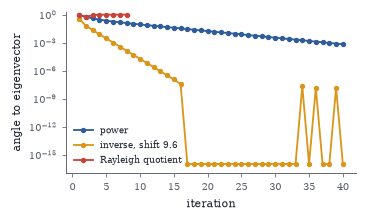

In [5]:
rng = np.random.default_rng(3); n = 100; Qm, _ = np.linalg.qr(rng.normal(size=(n, n))); lamv = np.r_[10.0, 8.5, rng.uniform(-5, 7, n - 2)]; A = Qm @ np.diag(lamv) @ Qm.T; target = Qm[:, 0]
ang = lambda x: np.sqrt(max(1 - (x @ target) ** 2, 1e-32))
x0 = rng.normal(size=n); x0 /= np.linalg.norm(x0); runs = {}
x = x0.copy(); r = []
for _ in range(40): x = A @ x; x /= np.linalg.norm(x); r.append(ang(x))
runs["power"] = r
x = x0.copy(); r = []; M = np.linalg.inv(A - 9.6 * np.eye(n))
for _ in range(40): x = M @ x; x /= np.linalg.norm(x); r.append(ang(x))
runs["inverse, shift 9.6"] = r
x = x0.copy(); r = []
for _ in range(2): x = A @ x; x /= np.linalg.norm(x); r.append(ang(x))
for _ in range(6):
    mu = x @ A @ x
    try: x = np.linalg.solve(A - mu * np.eye(n), x)
    except np.linalg.LinAlgError: break
    x /= np.linalg.norm(x); r.append(ang(x))
runs["Rayleigh quotient"] = r
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
for (lab, r), col in zip(runs.items(), [BLUE, GOLD, RED]): ax.semilogy(np.arange(1, len(r) + 1), np.maximum(r, 1e-17), "o-", ms=2.5, color=col, label=lab)
ax.set_xlabel("iteration"); ax.set_ylabel("angle to eigenvector"); ax.legend(fontsize=6); ax.set_ylim(1e-17, 2)

The QR algorithm on a symmetric tridiagonal $8\times8$ matrix. Left: without shifts, the subdiagonal entries $|(A_k)_{j+1,j}|$ decay linearly, each at its own rate $|\lambda_{j+1}/\lambda_j|$; the slowest pair takes hundreds of iterations. Right: with Wilkinson shifts and deflation, the last subdiagonal entry drops to machine precision in two or three steps, the matrix is deflated, and the next entry follows; all eigenvalues are found in about $16$ iterations.

(1e-18, 10)

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


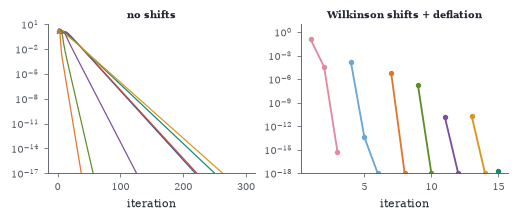

In [6]:
rng = np.random.default_rng(5); n = 8; d = np.linspace(1, 8, n) + rng.normal(0, 0.2, n); e = rng.uniform(0.5, 1, n - 1); T0 = np.diag(d) + np.diag(e, 1) + np.diag(e, -1)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9))
Ak = T0.copy(); hist = []
for k in range(300):
    Qk, Rk = np.linalg.qr(Ak); Ak = Rk @ Qk; hist.append(np.abs(np.diag(Ak, -1)))
hist = np.array(hist)
for j in range(n - 1): axs[0].semilogy(hist[:, j], color=PALETTE[j], lw=0.8)
axs[0].set_xlabel("iteration"); axs[0].set_title("no shifts", fontsize=6.5); axs[0].set_ylim(1e-17, 10)
Ak = T0.copy(); m = n; log = []; it = 0
while m > 1 and it < 60:
    a, b, c = Ak[m - 2, m - 2], Ak[m - 1, m - 2], Ak[m - 1, m - 1]; dlt = (a - c) / 2; mu = c - np.sign(dlt if dlt != 0 else 1) * b**2 / (abs(dlt) + np.hypot(dlt, b))
    Qk, Rk = np.linalg.qr(Ak[:m, :m] - mu * np.eye(m)); Ak[:m, :m] = Rk @ Qk + mu * np.eye(m); it += 1
    log.append((it, m, abs(Ak[m - 1, m - 2])))
    if abs(Ak[m - 1, m - 2]) < 1e-15 * (abs(Ak[m - 1, m - 1]) + abs(Ak[m - 2, m - 2])): Ak[m - 1, m - 2] = Ak[m - 2, m - 1] = 0; m -= 1
log = np.array(log)
for mm in np.unique(log[:, 1]):
    sel = log[:, 1] == mm; axs[1].semilogy(log[sel, 0], np.maximum(log[sel, 2], 1e-18), "o-", ms=2.5, color=PALETTE[int(mm) % 10])
axs[1].set_xlabel("iteration"); axs[1].set_title("Wilkinson shifts + deflation", fontsize=6.5); axs[1].set_ylim(1e-18, 10)

Ritz values from the Lanczos process for a symmetric $300\times300$ matrix with eigenvalues uniform in $[0,1]$ plus three outliers. Each column $k$ shows the $k$ eigenvalues of the tridiagonal $T_k$ (dots); the true extreme eigenvalues are the dashed lines. The outliers are found within a few iterations; the interior of the spectrum is resolved much later. Interlacing makes the extreme Ritz values monotone.

Text(0, 0.5, 'Ritz values')

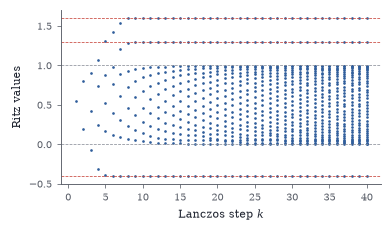

In [7]:
rng = np.random.default_rng(6); n = 300; lam = np.r_[rng.uniform(0, 1, n - 3), [1.3, 1.6, -0.4]]; Qm, _ = np.linalg.qr(rng.normal(size=(n, n))); A = (Qm * lam) @ Qm.T
def lanczos(A, b, k):
    Qs = [b / np.linalg.norm(b)]; al, be = [], []; qprev = np.zeros_like(b); bprev = 0.0
    for j in range(k):
        w = A @ Qs[-1] - bprev * qprev; a = Qs[-1] @ w; w -= a * Qs[-1]
        for q in Qs: w -= (q @ w) * q                     # full reorthogonalization
        al.append(a); bj = np.linalg.norm(w); be.append(bj); qprev, bprev = Qs[-1], bj; Qs.append(w / bj)
    return np.array(al), np.array(be[:-1])
al, be = lanczos(A, rng.normal(size=n), 40)
fig, ax = plt.subplots(figsize=(W * 0.75, 2.0))
for k in range(1, 41):
    th = np.linalg.eigvalsh(np.diag(al[:k]) + np.diag(be[:k - 1], 1) + np.diag(be[:k - 1], -1)); ax.plot(np.full(k, k), th, ".", color=BLUE, ms=1.5)
for v in (1.6, 1.3, -0.4, 0, 1): ax.axhline(v, color=RED if v in (1.6, 1.3, -0.4) else GRAY, ls="--", lw=0.5)
ax.set_xlabel("Lanczos step $k$"); ax.set_ylabel("Ritz values")

Conjugate gradients versus steepest descent on a $500\times500$ positive definite system with condition number $10^3$ (left: eigenvalues spread uniformly; right: the same extremes but most eigenvalues clustered near $1$). Energy-norm error against iterations: steepest descent (grey) is limited by the rate $(\kappa-1)/(\kappa+1)$ when the spectrum is spread, CG (blue) beats the Chebyshev bound $2((\sqrt\kappa-1)/(\sqrt\kappa+1))^k$ (dashed), and on the clustered spectrum CG converges far faster than the bound, which sees only $\kappa$.

/tmp/ipykernel_82454/842045820.py:6: RuntimeWarning: invalid value encountered in scalar divide
  Ap = A @ p; a = (r @ r) / (p @ Ap); x += a * p; rn = r - a * Ap; p = rn + (rn @ rn) / (r @ r) * p; r = rn; cg.append(en(x))


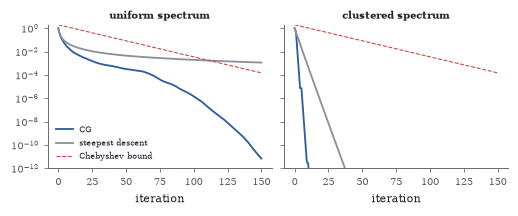

In [8]:
rng = np.random.default_rng(7); n = 500; kap = 1e3
def run(lam):
    Qm, _ = np.linalg.qr(rng.normal(size=(n, n))); A = (Qm * lam) @ Qm.T; xs = rng.normal(size=n); b = A @ xs; en = lambda x: np.sqrt((x - xs) @ A @ (x - xs))
    x = np.zeros(n); r = b.copy(); p = r.copy(); cg = [en(x)]
    for _ in range(150):
        Ap = A @ p; a = (r @ r) / (p @ Ap); x += a * p; rn = r - a * Ap; p = rn + (rn @ rn) / (r @ r) * p; r = rn; cg.append(en(x))
    x = np.zeros(n); sd = [en(x)]
    for _ in range(150):
        r = b - A @ x; x += (r @ r) / (r @ A @ r) * r; sd.append(en(x))
    return np.array(cg) / cg[0], np.array(sd) / sd[0]
fig, axs = plt.subplots(1, 2, figsize=(W, 1.85), sharey=True); ks = np.arange(151); rate = (np.sqrt(kap) - 1) / (np.sqrt(kap) + 1)
for ax, lam, ttl in [(axs[0], np.linspace(1, kap, n), "uniform spectrum"), (axs[1], np.r_[1, kap, 1 + 0.1 * rng.random(n - 2)], "clustered spectrum")]:
    cg, sd = run(lam); ax.semilogy(cg, color=BLUE, label="CG"); ax.semilogy(sd, color=GRAY, label="steepest descent"); ax.semilogy(ks, 2 * rate**ks, "--", color=RED, lw=0.7, label="Chebyshev bound")
    ax.set_xlabel("iteration"); ax.set_title(ttl, fontsize=6.5); ax.set_ylim(1e-12, 2)
axs[0].legend(fontsize=5.5)

Preconditioning the two-dimensional Laplacian on a $40\times40$ grid with a variable coefficient that spans four orders of magnitude. Relative residual of CG without preconditioning (grey), with the Jacobi (diagonal) preconditioner (gold), and with the symmetric Gauss–Seidel (SSOR) preconditioner $M=(D+L)D^{-1}(D+L)^{\mathsf T}$ built from the lower triangle (blue). The diagonal scaling removes the coefficient variation; the triangular factors also capture part of the coupling between neighbours, roughly halving the iteration count again.

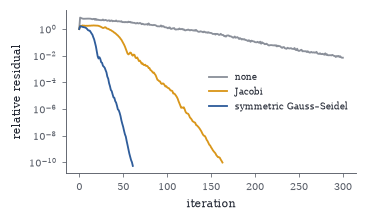

In [9]:
import scipy.sparse as sp, scipy.sparse.linalg as spla
m = 40; coef = np.exp(4 * np.sin(np.linspace(0, 3, m))[:, None] * np.cos(np.linspace(0, 2, m))[None, :])
idx = np.arange(m * m).reshape(m, m); rows, cols, vals = [], [], []
for i in range(m):
    for j in range(m):
        c = coef[i, j]; diag = 0
        for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            ii, jj = i + di, j + dj; w = 0.5 * (c + (coef[ii, jj] if 0 <= ii < m and 0 <= jj < m else c)); diag += w
            if 0 <= ii < m and 0 <= jj < m: rows.append(idx[i, j]); cols.append(idx[ii, jj]); vals.append(-w)
        rows.append(idx[i, j]); cols.append(idx[i, j]); vals.append(diag)
Ap = sp.csr_matrix((vals, (rows, cols)), shape=(m * m, m * m)); bp = np.ones(m * m)
def pcg(A, b, Minv, iters=300):
    x = np.zeros_like(b); r = b.copy(); z = Minv(r); p = z.copy(); res = [1.0]
    for _ in range(iters):
        Ap_ = A @ p; a = (r @ z) / (p @ Ap_); x += a * p; rn = r - a * Ap_; zn = Minv(rn); p = zn + (rn @ zn) / (r @ z) * p; r, z = rn, zn; res.append(np.linalg.norm(r) / np.linalg.norm(b))
        if res[-1] < 1e-10: break
    return res
dg = Ap.diagonal(); Lw = sp.tril(Ap, format="csr"); Up = sp.triu(Ap, format="csr")          # SSOR: M = (D+L) D^{-1} (D+U)
ssor = lambda r: spla.spsolve_triangular(Up, dg * spla.spsolve_triangular(Lw, r, lower=True), lower=False)
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
for Minv, col, lab in [(lambda r: r, GRAY, "none"), (lambda r: r / dg, GOLD, "Jacobi"), (ssor, BLUE, "symmetric Gauss–Seidel")]:
    ax.semilogy(pcg(Ap, bp, Minv), color=col, label=lab)
ax.set_xlabel("iteration"); ax.set_ylabel("relative residual"); ax.legend(fontsize=6)

In [10]:
rng = np.random.default_rng(8); n = 200; A = rng.normal(size=(n, n)) + n ** 0.5 * np.eye(n); x_true = rng.normal(size=n); b = A @ x_true
from scipy.linalg import lu_factor, lu_solve
lu32 = lu_factor(A.astype(np.float32)); x = lu_solve(lu32, b.astype(np.float32)).astype(np.float64)
for k in range(5):
    print(f"step {k}: relative error {np.linalg.norm(x - x_true) / np.linalg.norm(x_true):.2e}")
    r = b - A @ x; x = x + lu_solve(lu32, r.astype(np.float32)).astype(np.float64)
print("double-precision direct solve error:", f"{np.linalg.norm(np.linalg.solve(A, b) - x_true) / np.linalg.norm(x_true):.2e}")

step 0: relative error 6.82e-07
step 1: relative error 3.45e-13
step 2: relative error 1.49e-15
step 3: relative error 1.05e-15
step 4: relative error 1.14e-15
double-precision direct solve error: 2.37e-15


In [11]:
for k in range(1, 9):
    x = 10.0 ** -k; print(f"x=1e-{k}:  direct {(1 - np.cos(x)) / x**2:.15f}   stable {2 * np.sin(x / 2) ** 2 / x**2:.15f}")

x=1e-1:  direct 0.499583472197418   stable 0.499583472197423
x=1e-2:  direct 0.499995833347366   stable 0.499995833347222
x=1e-3:  direct 0.499999958325503   stable 0.499999958333335
x=1e-4:  direct 0.499999996961265   stable 0.499999999583333
x=1e-5:  direct 0.500000041370185   stable 0.499999999995833
x=1e-6:  direct 0.500044450291171   stable 0.499999999999958
x=1e-7:  direct 0.499600361081320   stable 0.500000000000000
x=1e-8:  direct 0.000000000000000   stable 0.500000000000000


In [12]:
eps = 1e-8; A3 = np.array([[1, 1], [eps, 0], [0, eps]]); b3 = np.array([2.0, eps, eps])     # exact solution (1, 1)
print("cond(A) =", f"{np.linalg.cond(A3):.2e}", "  A^T A as computed:", (A3.T @ A3).tolist())
Q3, R3 = np.linalg.qr(A3); print("QR solution:", np.linalg.solve(R3, Q3.T @ b3))

cond(A) = 1.41e+08   A^T A as computed: [[1.0, 1.0], [1.0, 1.0]]
QR solution: [1. 1.]


In [13]:
A2 = np.array([[2.0, 1], [1, 1]]); lam = np.linalg.eigvalsh(A2); Ak = A2.copy(); prev = abs(Ak[1, 0])
for k in range(1, 9):
    Q, R = np.linalg.qr(Ak); Ak = R @ Q; cur = abs(Ak[1, 0]); print(f"k={k}: |(A_k)_21| = {cur:.3e}   ratio to previous step = {cur / prev:.4f}"); prev = cur
print("lambda2/lambda1 =", round(lam[0] / lam[1], 4))

k=1: |(A_k)_21| = 2.000e-01   ratio to previous step = 0.2000
k=2: |(A_k)_21| = 2.941e-02   ratio to previous step = 0.1471
k=3: |(A_k)_21| = 4.292e-03   ratio to previous step = 0.1459
k=4: |(A_k)_21| = 6.262e-04   ratio to previous step = 0.1459
k=5: |(A_k)_21| = 9.136e-05   ratio to previous step = 0.1459
k=6: |(A_k)_21| = 1.333e-05   ratio to previous step = 0.1459
k=7: |(A_k)_21| = 1.945e-06   ratio to previous step = 0.1459
k=8: |(A_k)_21| = 2.837e-07   ratio to previous step = 0.1459
lambda2/lambda1 = 0.1459


In [14]:
rng = np.random.default_rng(1); n = 100; Qm, _ = np.linalg.qr(rng.normal(size=(n, n))); lam = rng.choice([1.0, 3.0, 10.0, 50.0], n); A = (Qm * lam) @ Qm.T; b = rng.normal(size=n)
x = np.zeros(n); r = b.copy(); p = r.copy()
for k in range(1, 7):
    Ap = A @ p; a = (r @ r) / (p @ Ap); x += a * p; rn = r - a * Ap; p = rn + (rn @ rn) / (r @ r) * p; r = rn
    print(f"iteration {k}: relative residual {np.linalg.norm(b - A @ x) / np.linalg.norm(b):.2e}")

iteration 1: relative residual 1.43e+00
iteration 2: relative residual 7.32e-01
iteration 3: relative residual 3.11e-01
iteration 4: relative residual 3.66e-13
iteration 5: relative residual 5.03e-15
iteration 6: relative residual 2.26e-15


In [15]:
def arnoldi(A, b, k):
    n = len(b); Q = np.zeros((n, k + 1)); H = np.zeros((k + 1, k)); Q[:, 0] = b / np.linalg.norm(b)
    for j in range(k):
        w = A @ Q[:, j]
        for i in range(j + 1): H[i, j] = Q[:, i] @ w; w -= H[i, j] * Q[:, i]
        H[j + 1, j] = np.linalg.norm(w); Q[:, j + 1] = w / H[j + 1, j]
    return Q, H
rng = np.random.default_rng(4); A50 = rng.normal(size=(50, 50)); Qa, Ha = arnoldi(A50, rng.normal(size=50), 10)
print("||A Q_k - Q_{k+1} H_k|| =", f"{np.linalg.norm(A50 @ Qa[:, :10] - Qa @ Ha):.1e}", "   ||Q^T Q - I|| =", f"{np.linalg.norm(Qa.T @ Qa - np.eye(11)):.1e}")

||A Q_k - Q_{k+1} H_k|| = 6.3e-15    ||Q^T Q - I|| = 6.9e-16
